In [1]:
%load_ext autoreload
%autoreload 2    

In [2]:
import sys
from pathlib import Path
root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1  # we will reuse some things from last tutorial
import Project2
from datasets import load_dataset, concatenate_datasets, DatasetDict
import numpy as np
import matplotlib.pyplot as plt
import itertools
import re 
from sklearn.metrics import precision_recall_fscore_support
import arviz as az
import pandas as pd
import nltk
nltk.download('opinion_lexicon')

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     /Users/mac/nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


True

In [3]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

In [4]:
topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]
outcome_space = Project1.clslib.NamedClasses(['none', 'against', 'favor'])
per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

KEEP_SPECIAL = {"<user>", "<hashtag>", "<number>", "<repeat>", "<url>",
                "<elong>", "<allcaps>", "<smile>", "<lolface>", "<sadface>", "<neutralface>", "<heart>"}

# Extra preprocessing
_EYES, _NOSE = r"[8:=;]", r"['`\-]?"

def _hashtag(m):
    body = m.group(0)[1:].replace("_", " ")
    if body == body.upper():
        return f"<HASHTAG> {body.lower()} <ALLCAPS>"
    parts = [p for p in re.split(r"(?=[A-Z])|\s+", body) if p]
    return "<HASHTAG> " + " ".join(parts)

def glove_twitter_preprocess(text: str) -> str:
    """Port of Stanford's preprocess-twitter.rb (GloVe Twitter preprocessing)."""
    text = re.sub(r"https?://\S+\b|www\.(?:\w+\.)+\S*", "<URL>", text)
    text = text.replace("/", " / ")
    text = re.sub(r"@\w+", "<USER>", text)
    text = re.sub(rf"{_EYES}{_NOSE}[)d]+|[)d]+{_NOSE}{_EYES}", "<SMILE>", text, flags=re.I)
    text = re.sub(rf"{_EYES}{_NOSE}p+", "<LOLFACE>", text, flags=re.I)
    text = re.sub(rf"{_EYES}{_NOSE}\(+|\)+{_NOSE}{_EYES}", "<SADFACE>", text)
    text = re.sub(rf"{_EYES}{_NOSE}[/|l*]", "<NEUTRALFACE>", text)
    text = text.replace("<3", "<HEART>")
    text = re.sub(r"[-+]?[.\d]*[\d]+[:,.\d]*", "<NUMBER>", text)
    text = re.sub(r"#\S+", _hashtag, text)
    text = re.sub(r"([!?.]){2,}", lambda m: f"{m.group(1)} <REPEAT>", text)
    text = re.sub(r"\b(\S*?)(.)\2{2,}\b", lambda m: f"{m.group(1)+m.group(2)} <ELONG>", text)
    text = re.sub(r"(?<![<\w])[A-Z]{2,}(?![>\w])", lambda m: f"{m.group(0).lower()} <ALLCAPS>", text)
    text = text.lower()
    text = re.sub(r"<[a-z]+>", lambda m: m.group(0) if m.group(0) in KEEP_SPECIAL else "", text)
    return re.sub(r"\s+", " ", text).strip()



# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topics
# dataset = per_topic[0]

dataset = dataset.map(
    lambda x: {"text": glove_twitter_preprocess(x["text"].replace(" #SemST", ""))}
)
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

# Recover the original topic for each test tweet
# Uses the same ordering as concatenate_datasets()

topic_labels = [
    topic.replace("stance_", "")
    for topic, ds in zip(topics, per_topic)
    for _ in range(len(ds["test"]))
]

assert len(topic_labels) == len(dataset["test"])

if "topic" not in dataset["test"].column_names:
    dataset["test"] = dataset["test"].add_column(
        "topic", topic_labels
    )

comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])

In [5]:
from Project2.utils import boc_emb
print(
    Project2.utils.embeddings_to_str(
        {
            ".": boc_emb("."),        
            "!": boc_emb("!"),
            "a": boc_emb("a"),
            "another": boc_emb("another"),
            "day": boc_emb("day"),
            "good": boc_emb("good"),
            "just": boc_emb("just"),
            "regular": boc_emb("regular"),        
        },
        floatfmt=".0f"
    )
)

.        1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
!        1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
a        0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
another  0  1  0  0  0  1  0  0  1  0  0  0  0  0  1  1  0  0  1  0  1  0  0  0  0  0  0
day      0  1  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0
good     0  0  0  0  1  0  0  1  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0
just     0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  1  1  1  0  0  0  0  0
regular  0  1  0  0  0  1  0  1  0  0  0  0  1  0  0  0  0  0  2  0  0  1  0  0  0  0  0


In [6]:
rng = np.random.RandomState(42)
demo_dim = 10
demo_emb_table = {
    "<unk>": rng.normal(size=demo_dim),
    ".": rng.normal(size=demo_dim),
    "!": rng.normal(size=demo_dim),
    "a": rng.normal(size=demo_dim),
    "another": rng.normal(size=demo_dim),
    "bad": rng.normal(size=demo_dim),
    "day": rng.normal(size=demo_dim),
    "good": rng.normal(size=demo_dim),
    "just": rng.normal(size=demo_dim),
    "regular": rng.normal(size=demo_dim),        
}
print(Project2.utils.embeddings_to_str(demo_emb_table, floatfmt=".2f"))

<unk>     0.50  -0.14   0.65   1.52  -0.23  -0.23   1.58   0.77  -0.47   0.54
.        -0.46  -0.47   0.24  -1.91  -1.72  -0.56  -1.01   0.31  -0.91  -1.41
!         1.47  -0.23   0.07  -1.42  -0.54   0.11  -1.15   0.38  -0.60  -0.29
a        -0.60   1.85  -0.01  -1.06   0.82  -1.22   0.21  -1.96  -1.33   0.20
another   0.74   0.17  -0.12  -0.30  -1.48  -0.72  -0.46   1.06   0.34  -1.76
bad       0.32  -0.39  -0.68   0.61   1.03   0.93  -0.84  -0.31   0.33   0.98
day      -0.48  -0.19  -1.11  -1.20   0.81   1.36  -0.07   1.00   0.36  -0.65
good      0.36   1.54  -0.04   1.56  -2.62   0.82   0.09  -0.30   0.09  -1.99
just     -0.22   0.36   1.48  -0.52  -0.81  -0.50   0.92   0.33  -0.53   0.51
regular   0.10   0.97  -0.70  -0.33  -0.39  -1.46   0.30   0.26   0.01  -0.23


* We can use this kind of resource to train a _binary classifier_ intended to classify a pair of words as 1 (for words that do co-occur) vs. 0 (for words that do not co-occur) on the basis of the _similarity_ of the vectors that represent those words. This way we can fit our randomly initialised embeddings (in `demo_emb_table`) to the observed data, which will in principle improve the ability of our embeddings to discriminate co-occurring to non-co-occuring pairs. In other words, this will improve their ability to capture a notion of similarity, one useful to predict patterns of co-occurrence in text.
* We sketch and demo the model below: for didactic purposes, rather than using torch.nn.Module, we will implement the steps of SGD more transparently for you (we are still going to rely on torch for automatic differentiation of our loss node; for loss, we will use an estimate of the negative of the model's log-likelihood).

In [7]:
import scipy as sp
import scipy.special
from scipy.special import expit  # this is the same as the sigmoid function
import torch
import torch.nn as nn
import torch.autograd

class DemoLogisticCooccurrenceClassifier:

    def __init__(self, table: dict, unk="<unk>"):        
        """
        table: a dict mapping words (each a string) to their embeddings (each an np array)
        unk: the special word (str) to catch all unknown words
        device: a torch device (cpu is fine, this is just a demo)
        """
        # we construct trainable parameters for the embeddings, and initialise them with the 
        # arrays in the constructor
        self.table = {w: nn.Parameter(torch.tensor(v, dtype=torch.float32)) for w, v in table.items()}
        self.unk = unk

    def __call__(self, t: str, c: str):
        """
        Return the pmf over (co-occur=False, co-occur=True; 0 and 1, respectively) 
        given two words (t and c).

        For didactic purposes, here we deal with 1 word pair at a time.
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        # here we use the dot product as our notion of similarity 
        # note that dot product is related to cosine similarity (this may come in handy later on)
        s = torch.dot(u, v)
        # now we parameterise a pmf for binary outcomes using
        # the sigmoid of the dot product (scipy calls it expit)
        # this makes the dot product s the logit or score of a logistic regressor
        p = torch.sigmoid(s)        
        # we could return only p, then interpert this as the pfm of Bernoulli(p)
        # or return [1-p, p], then interpret this as the pmf of Categorical([1-p, p])
        # we will opt for the latter just so it looks more similar to last week's
        return torch.stack((1 - p, p), dim=-1)

    def loss(self, t, c, label):        
        """
        The loss for parameter estimation. We use an estimate of the negative of the model's log-likelihood.
        This is an _estimate_ because it is based on a single data point 
        (the exact log-likelihood function would use an entire training set).

        So, for an observed pair (t, c) with a given label, the loss is then
        - log p(label|t, c)

        We obtain the pmf, assess the prob it assigns to the observed label, and then compute the quantity above.        
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        pmf = self(t, c)
        return - torch.log(pmf[label])
    
    def loss_and_grads(self, t, c, label): 
        """
        The loss for parameter estimation and the gradients of the parameters involved in the computation of the loss. 
        For loss see the docstring of the method 'loss'.

        In this model, the estimated loss using (t, c, label) involves two parameter vectors, 
            * u = emb(t)
            * and v = emb(c)
        The other parameters are not involved in the computation, hence their grads are 0.

        Here we instantiate the loss and use autograd.grad to obtain gradients wrt u and v, 
         which we return in a dict (indexed by t and c).

        These grad vectors can be used to update the embeddings, see method 'update_embs'.
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        pmf = self(t, c)
        loss = - torch.log(pmf[label])
        params = tuple(v for v in self.table.values())
        grads = torch.autograd.grad(loss, (u,v))
        return loss, {t: grads[0], c: grads[1]}

    def update_embs(self, grads: dict, lr=0.1):        
        """
        Perform an in-place update of the embeddings whose grads are given. 
        As we are performing gradient descent on the loss, the simplest form of SGD update boils down to
            emb(w) = emb(w) - lr * grad(w)
            
        grads: dict mapping words (each a string) and the gradient vectors for their corresponding embeddings
            (these are obtained from loss_and_grads)
        lr: a learning rate (use less than 1.0)
        """
        # we are explicitly detaching the grad vector from the graph
        # this is to avoid a situation where you might change some options in autograd.grad 
        # and inadvertently compute grad of grad when playing with multiple calls to loss_and_grad
        with torch.no_grad():
            for w, g in grads.items():
                self.table[w].add_(g, alpha=-lr)

In [8]:
import shutil
import zipfile


def convert_glove_twitter(destination="glove-twitter-200.zip"):
    """Download Stanford's glove.twitter.27B.zip (~1.4 GB) and keep only the 200d    file, re-zipped."""
    from huggingface_hub import hf_hub_download

    src = hf_hub_download("stanfordnlp/glove", "glove.twitter.27B.zip")
    with zipfile.ZipFile(src) as zin:
        member = next(n for n in zin.namelist() if n.endswith("100d.txt"))
        with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as zout:
            with zin.open(member) as fin, zout.open(member, "w", force_zip64=True) as fout:
                shutil.copyfileobj(fin, fout)

In [9]:
from pathlib import Path
from urllib.request import urlopen
import shutil

def download_pretrained(option):
    """
    You can use this to download GloVe (or similar) model using wget. 
    It's fine to download it through other means, but don't unzip the file (the rest of the notebook can 
    handle the file in its zipped format).

    This function returns the path which you can use for the loader class that follows.

    The function will skip the download if it detects the file in disk. If the file in disk is corrupted, you will have to delete the file first.
    """
    if option == 'glove':
        destination = "glove.2024.wikigiga.50d.zip"
        dims = 50
        skip_first = False
    elif option == 'fasttext':
        destination = "wiki-news-300d-1M.vec.zip"
        dims = 300
        skip_first = True
    elif option == 'glove-twitter':
        destination = "glove-twitter-100.zip"
        dims = 100
        skip_first = False
    else:
        raise ValueError(f"Unkonwn option: {option}")
        
    if not Path(destination).is_file():
        if option == 'glove':
            !wget -O glove.2024.wikigiga.50d.zip 'https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download'
        elif option == 'fasttext':
            !wget https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip
        elif option == 'glove-twitter':
            convert_glove_twitter(destination)
    return destination, dims, skip_first

Here we download the model:

In [10]:
%%time
# depends on internet connection (but say 5 minutes or less)
embtable_version, embtable_dims, embtable_metadata = download_pretrained('glove-twitter') # in case stanford.edu is down, use fasttext (but glove is preferred)
embtable_version, embtable_dims, embtable_metadata

CPU times: user 42 μs, sys: 13 μs, total: 55 μs
Wall time: 52 μs


('glove-twitter-100.zip', 100, False)

In `Project2/clslib.py`, you will find `PretrainedEmbeddings`, which can be used to load embeddings to memory. We've documented it well for you, in case you want to familiarise yourself with the relevant steps.

In [11]:
%%time
# about 30 seconds for GloVe
trained_emb_model = Project2.clslib.PretrainedEmbeddings(embtable_version, embtable_dims, skip_first_line=embtable_metadata)

CPU times: user 46 s, sys: 662 ms, total: 46.7 s
Wall time: 46.8 s


In [12]:
print("Shape of embedding matrix:", trained_emb_model.vectors.shape)
print("Size of vocabulary:", len(trained_emb_model.vocab))
print(f"UNK token {trained_emb_model.vocab.default_index}:{trained_emb_model.vocab.default_word}") 
print(f"PAD token {trained_emb_model.vocab.index(trained_emb_model.pad_token)}:{trained_emb_model.pad_token}")
print("First few entries in the vocabulary:")
for _, (i, w) in zip(range(10), trained_emb_model.vocab.items()):
    print(f"{i}:{w}")

Shape of embedding matrix: (1193515, 100)
Size of vocabulary: 1193515
UNK token 1:<unk>
PAD token 0:<pad>
First few entries in the vocabulary:
0:<pad>
1:<unk>
2:<user>
3:.
4::
5:rt
6:,
7:<repeat>
8:<hashtag>
9:<number>


And here we demo the key functions of PretrainedEmbeddings:

In [13]:
for word in ['person', 'human', 'city', 'place', 'camera-ready']:
    print(word, word in trained_emb_model, trained_emb_model.index(word), trained_emb_model.embed_word(word).shape)

person True 419 (100,)
human True 2270 (100,)
city True 936 (100,)
place True 910 (100,)
camera-ready False 1 (100,)


You can see an embedding if you like (though like this it's hard to spot anything useful in it):

In [14]:
trained_emb_model.embed_word('person')

array([ 5.7202e-01,  2.8743e-01, -2.3105e-01,  4.6566e-01,  5.2006e-01,
        4.8470e-01,  3.5585e-01, -2.1534e-01, -8.5127e-02,  2.8167e-01,
        1.6501e-01, -2.0768e-01, -4.7848e+00, -5.6471e-01, -5.0167e-01,
        8.5870e-01,  6.7972e-01, -2.0340e-01, -3.7268e-01, -2.0217e-02,
        8.4978e-01,  3.3443e-01, -6.4509e-01, -7.0772e-02, -2.8161e-01,
        4.9941e-01, -4.8399e-01, -1.3443e-01, -7.4470e-01,  4.4267e-01,
        5.0786e-01, -7.5187e-01, -3.1850e-01, -6.3969e-02, -1.9756e-02,
        2.4246e-01,  7.2916e-01,  2.7826e-01, -9.2798e-02, -5.4107e-01,
       -8.5371e-01,  3.2970e-01,  2.5588e-01,  4.7478e-02,  1.2265e-04,
        8.9037e-03,  5.1257e-01, -4.1418e-02, -6.1939e-01,  3.6442e-02,
       -3.4586e-01,  3.5043e-01,  4.2794e-02, -2.8167e-01, -1.5954e-01,
        7.0789e-01, -6.2910e-01,  5.8412e-02, -3.2060e-01,  3.7044e-01,
        1.5725e-01, -1.8764e-01,  1.1346e-01,  1.7080e-01,  3.3297e-01,
       -1.8902e-01,  8.8933e-02,  7.2055e-01, -4.6054e-01,  3.25

In [15]:
pos_words, neg_words = Project2.utils.sample_pos_and_neg_words(trained_emb_model)
print(f"{len(pos_words)} positive words; sample:", " ".join(pos_words[:10]))
print(f"{len(neg_words)} negative words; sample:", " ".join(neg_words[:10]))

1000 positive words; sample: stunningly aspire dashing saver non-violence mightily entrancing outstandingly effectively unquestionably
1000 negative words; sample: rejecting smallish distrust ineligible friggin sputter unsettling overshadow cartoonish hawkish


In [16]:
def cos_similarity(u, v):  
    """
    Return the cosine similarity (a real number) of the two words in the embedding space of our model.
    """      
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

def topk_ids(v, E, k=10):
    """
    word embedding: a D-dimensional vector
    E: our model's embedding matrix as a numpy array of shape [V, D]
    k: how many nearest neighbours we want to find

    Return a list with the k word ids that are nearest to the input word embedding v
     in embedding space according to cosine similarity. 
    """   
    all_similarities = []
    for i in range(E.shape[0]):
        all_similarities.append(cos_similarity(v, E[i]))
    all_similarities = np.nan_to_num(all_similarities, nan=-1.0)
    return np.argsort(all_similarities)[::-1][:k]

In [17]:
def demo_similarity(words, model):
    for i, word1 in enumerate(words):
        for word2 in words[i:]:
            sim = cos_similarity(model.embed_word(word1), model.embed_word(word2))
            print(f"cos_similarity({word1}, {word2}) = {sim:.4f}")

def demo_topk(words, k, model):
    for word in words:
        id2word = dict(model.vocab.items())
        topk_ids_list = topk_ids(model.embed_word(word), model.vectors, k)
        topk_words = [id2word[i] for i in topk_ids_list]
        print(f"top-{k} nearest neighbours of {word}: {topk_words}")

def demo_analogy(a, b, c, k, model):
    id2word = dict(model.vocab.items())
    v = model.embed_word(a) - model.embed_word(b) + model.embed_word(c)
    topk_ids_list = topk_ids(v, model.vectors, k)
    topk_words = [id2word[i] for i in topk_ids_list]
    print(f"Q: {a} - {b} + {c}")
    for w in topk_words:
        print(f" {w}")

In [18]:
"""
try:
    from Project2 import solutions
except ImportError:
    print("You need your own implementation of cos_similarity")
else:
print("# Similarity")
demo_similarity(['person', 'human', 'place', 'city', 'car'], trained_emb_model)    
print("\n# Top-k")
demo_topk(['woman', 'man', 'king', 'queen', 'professor', 'nurse', 'positive'], 10, trained_emb_model)        
print("\n# Analogies")
for a, b, c in [('king', 'man', 'woman'), ('professor', 'man', 'woman'), ('nurse', 'man', 'woman')]:
    demo_analogy(a, b, c, 10, trained_emb_model)
    demo_analogy(a, c, b, 10, trained_emb_model)
    print()
"""

'\ntry:\n    from Project2 import solutions\nexcept ImportError:\n    print("You need your own implementation of cos_similarity")\nelse:\nprint("# Similarity")\ndemo_similarity([\'person\', \'human\', \'place\', \'city\', \'car\'], trained_emb_model)    \nprint("\n# Top-k")\ndemo_topk([\'woman\', \'man\', \'king\', \'queen\', \'professor\', \'nurse\', \'positive\'], 10, trained_emb_model)        \nprint("\n# Analogies")\nfor a, b, c in [(\'king\', \'man\', \'woman\'), (\'professor\', \'man\', \'woman\'), (\'nurse\', \'man\', \'woman\')]:\n    demo_analogy(a, b, c, 10, trained_emb_model)\n    demo_analogy(a, c, b, 10, trained_emb_model)\n    print()\n'

In [19]:
class Tokenizer:
    def tokens(self, text: str) -> list:
        """Tokenize as a list of string tokens"""
        raise NotImplementedError("Implement me in subclass")
    def ids(self, text: str) -> list:
        """Tokenize as a list of token ids"""
        raise NotImplementedError("Implement me in subclass")

In [20]:

nltk.download('stopwords')
# Project2.clslib.BasicTokenizer?

[nltk_data] Downloading package stopwords to /Users/mac/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [21]:
from tabulate import tabulate

demo_texts = ['Dog bites man.', 'This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.']

tokenizer_for_bow = Project2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=True, 
    remove_stopwords=True, 
    language='english',
    vocab=trained_emb_model.vocab
)

for text in demo_texts:
    print(text)
    print(tabulate(list(zip(tokenizer_for_bow.ids(text), tokenizer_for_bow.tokens(text))), headers=['id', 'token']))    
    print()

Dog bites man.
   id  token
-----  -------
 1319  dog
12800  bites
  248  man

This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.
   id  token
-----  ---------
11852  tutorial
12623  offered
  804  part
    1  nlp1
18787  msc
 2199  level
 1605  course
  261  ai
14421  programme
28976  uva



In [22]:
tokenizer_for_rnn = Project2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=False,
    remove_stopwords=False, 
    language='english',
    vocab=trained_emb_model.vocab
)

for text in demo_texts:
    print(text)
    print(tabulate(list(zip(tokenizer_for_rnn.ids(text), tokenizer_for_rnn.tokens(text))), headers=['id', 'token']))    
    print()

Dog bites man.
   id  token
-----  -------
 1319  dog
12800  bites
  248  man
    3  .

This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.
   id  token
-----  ---------
   55  this
11852  tutorial
   34  is
12623  offered
  126  as
  804  part
   41  of
    1  nlp1
    6  ,
  174  an
18787  msc
 2199  level
 1605  course
   37  in
   15  the
  261  ai
14421  programme
   41  of
   15  the
28976  uva
    3  .



In [23]:
# Tokenizer wrapper, fixes "<", "hasthag", ">" issue

SPECIAL = re.compile(r"(<[a-z]+>)")

class SpecialKeepingTokenizer:
    def __init__(self, base):
        self.base = base
    def __getattr__(self, name):
        return getattr(self.base, name)
    def tokens(self, text):
        out = []
        for piece in SPECIAL.split(text):
            if SPECIAL.fullmatch(piece):
                out.append(piece)
            elif piece.strip():
                out.extend(self.base.tokens(piece))
        return out
    def ids(self, text):
        return [self.base.vocab.index(t) for t in self.tokens(text)]

tokenizer_for_bow = SpecialKeepingTokenizer(tokenizer_for_bow)
tokenizer_for_rnn = SpecialKeepingTokenizer(tokenizer_for_rnn)

In [24]:
# Sanity check, does the tokenization help

raw = "#HillaryClinton is NOT it!!! #lovewins 2016 @someone sooo good"
print(glove_twitter_preprocess(raw))
print(tokenizer_for_rnn.tokens(glove_twitter_preprocess(raw)))
print(tokenizer_for_bow.tokens(glove_twitter_preprocess(raw)))

<hashtag> hillary clinton is not <allcaps> it! <repeat> <hashtag> lovewins <number> <user> so <elong> good
['<hashtag>', 'hillary', 'clinton', 'is', 'not', '<allcaps>', 'it', '!', '<repeat>', '<hashtag>', 'lovewins', '<number>', '<user>', 'so', '<elong>', 'good']
['<hashtag>', 'hillary', 'clinton', '<allcaps>', '<repeat>', '<hashtag>', 'lovewins', '<number>', '<user>', '<elong>', 'good']


In [25]:
# Shows what tokens are not covered by the tokenizer

from collections import Counter

def coverage(texts, tokenizer, emb_model):
    unk = emb_model.vocab.default_index
    n_tok = n_oov = 0
    all_types, oov_types = set(), Counter()
    for t in texts:
        for tok, i in zip(tokenizer.tokens(t), tokenizer.ids(t)):
            n_tok += 1
            all_types.add(tok)
            if i == unk:
                n_oov += 1
                oov_types[tok] += 1
    print(f"token coverage: {1 - n_oov/n_tok:.3f}")
    print(f"type coverage:  {1 - len(oov_types)/len(all_types):.3f}")
    print(oov_types.most_common(30))

coverage(comb_dataset["text"], tokenizer_for_bow, trained_emb_model)
coverage(comb_dataset["text"], tokenizer_for_rnn, trained_emb_model)

token coverage: 0.979
type coverage:  0.914
[('equaility', 10), ('prolifegen', 8), ('ruth_blane', 8), ('prolifeyouth', 7), ('youthgen', 5), ('cfcc', 5), ('antifeminism', 5), ('gamergate', 5), ('hillarys', 5), ('lovewins', 4), ('freeallfour', 4), ('unitedblue', 4), ('peipoli', 3), ('roevwade', 3), ('isright', 3), ('hachhethu', 3), ('mainau', 3), ('glblwarmingnews', 3), ('carbontaxscam', 3), ('robertredford', 3), ('alaac', 3), ('killallmen', 3), ('streetharassment', 3), ('sjws', 3), ('hillaryclinton', 3), ('peivotes', 2), ('preborn', 2), ('worstargumentever', 2), ('abvote', 2), ('abortionrights', 2)]
token coverage: 0.985
type coverage:  0.894
[('equaility', 10), ('prolifegen', 8), ("y'all", 8), ('ruth_blane', 8), ('prolifeyouth', 7), ('-pope', 5), ("gov't", 5), ('-ps', 5), ('cfcc', 5), ('antifeminism', 5), ('gamergate', 5), ('hillarys', 5), ("'t", 4), ('lovewins', 4), ('freeallfour', 4), ('unitedblue', 4), ('peipoli', 3), ('-mother', 3), ('roevwade', 3), ('-prov', 3), ('hachhethu', 3), 

In [26]:
E = np.asarray(trained_emb_model.vectors, dtype=np.float32)
E_norm = E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-8)
id2word = dict(trained_emb_model.vocab.items())

def neighbours(word, k=10):
    sims = E_norm @ E_norm[trained_emb_model.index(word)]
    top = np.argsort(-sims)[: k + 1]
    return [id2word[i] for i in top if id2word[i] != word][:k]

# Closest neighbours of the topic words and some terms and their score after the word
for w in ["abortion", "atheism", "climate", "feminist", "hillary"]:
    if w in trained_emb_model:
        print(f"{w:10}", [f"{n}:{cos_similarity(trained_emb_model.embed_word(w), trained_emb_model.embed_word(n)):.3f}" for n in neighbours(w)])

# a few similarity pairs: related vs unrelated
def cos(a, b):
    return float(E_norm[trained_emb_model.index(a)] @ E_norm[trained_emb_model.index(b)])

for a, b in [("barack", "obama"), ("hillary", "clinton"), ("abortion", "pro-life"),
             ("atheist", "religion"), ("hillary", "banana")]:
    if a in trained_emb_model and b in trained_emb_model:
        print(f"cos({a}, {b}) = {cos(a, b):.3f}")

abortion   ['abortions:0.780', 'marriage:0.738', 'parenthood:0.688', 'pro-life:0.686', 'contraception:0.684', 'rape:0.680', 'obamacare:0.678', 'homosexuality:0.675', 'prolife:0.671', 'rights:0.659']
atheism    ['christianity:0.824', 'atheist:0.774', 'judaism:0.737', 'humanism:0.729', 'atheists:0.717', 'catholicism:0.681', 'spirituality:0.667', 'religion:0.666', 'atheistrollcall:0.662', 'belief:0.658']
climate    ['climatechange:0.820', 'economic:0.792', 'environmental:0.781', 'environment:0.751', 'policy:0.737', 'warming:0.730', 'sustainability:0.701', 'economy:0.691', 'threat:0.676', 'inequality:0.673']
feminist   ['feminism:0.765', 'atheist:0.705', 'feminists:0.691', 'liberal:0.690', 'conservative:0.679', 'religious:0.665', 'marxist:0.664', 'humanist:0.646', 'sexist:0.640', 'sexism:0.640']
hillary    ['clinton:0.906', 'obama:0.741', 'barack:0.728', 'christie:0.718', 'bush:0.707', 'kerry:0.699', 'benghazi:0.698', 'romney:0.685', 'potus:0.683', 'biden:0.674']
cos(barack, obama) = 0.894

In [27]:
ex_batch = torch.tensor(
    [
        [1, 2, 3, 0],
        [6, 2, 0, 0],
        [2, 1, 4, 5]
    ]
) 
ex_batch

tensor([[1, 2, 3, 0],
        [6, 2, 0, 0],
        [2, 1, 4, 5]])

In [28]:
torch.sum(ex_batch.ne(0), dim=-1) == torch.tensor([3, 2, 4])

tensor([True, True, True])

In [29]:
from torch.nn.utils.rnn import pad_sequence   

def collate_sequences(sequences, padding_value=0):    
    """
    This is a helper to batch tokenized sequences of variable length into a torch tensor with shape (num_sequences, longest_seq_length)
    sequences: list of tokenized texts (each text is a list of token ids)
    padding_value: the id of the pad symbol
    """
    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
    x = pad_sequence([torch.tensor(seq, dtype=torch.long) for seq in sequences], batch_first=True, padding_value=padding_value)
    return x

In [30]:
collate_sequences([tokenizer_for_bow.ids(text) for text in demo_texts], tokenizer_for_bow.vocab.index(trained_emb_model.pad_token))

tensor([[ 1319, 12800,   248,     0,     0,     0,     0,     0,     0,     0],
        [11852, 12623,   804,     1, 18787,  2199,  1605,   261, 14421, 28976]])

In [31]:
import torch
import torch.nn as nn

class EmbedAndPoolEncoder(nn.Module):
    """
    This encoder embeds a sequence of token ids and then pools the result along sequence length using
    sum or mean.
    """
    def __init__(self, embedding_matrix, average_pool=True, padding_idx=0, freeze_embeddings=True):
        """
        embedding_matrix: a torch tensor of shape (vocab_size, emb_dim)
        average_pool: use True for mean and False for sum
        padding_idx: the id of the pad token (this is for batched computation)
            suppose we are batching three sequences [1, 2, 3], [6, 2] and [2, 1, 4, 5]
            as they differ in length, we use the following trick to batch them into a single tensor
            [
                [1, 2, 3, 0],
                [6, 2, 0, 0],
                [2, 1, 4, 5]
            ]
            that is we extend the shorter sequences with 0s until they match the longest sequence
        freeze_embeddings: tells torch that we are not updating the parameters in the embedding matrix
        """
        super().__init__()
        self.average_pool = average_pool
        # Pretrained embeddings
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, 
            freeze=freeze_embeddings,
            padding_idx=padding_idx
        )        
        

    @property
    def enc_dim(self):
        return self.embedding.embedding_dim

    def forward(self, x):     
        """
        Encodes each sequence in the batch as a single vector of size emb_dim.
        
        x: token ids with shape (batch_size, max_seq_length, emb_dim)        
        """
        # [..., max_seq_length, emb_dim]
        e = self.embedding(x)  
        mask = x.ne(self.embedding.padding_idx).unsqueeze(-1)
        h = torch.sum(e * mask, dim=1)
        if self.average_pool:
            lenghts = mask.sum(dim=-2).clamp(min=1)
            h = h / lenghts
        return h

In [32]:
def test_embed_and_pool(emb_vectors, pad_id, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_embed_and_pool_encoder = EmbedAndPoolEncoder(
            torch.tensor(emb_vectors, dtype=torch.float32), 
            freeze_embeddings=True, 
            padding_idx=pad_id
        )
        your_h = your_embed_and_pool_encoder(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_embed_and_pool_encoder = Project2.clslib.EmbedAndPoolEncoder(
            torch.tensor(emb_vectors, dtype=torch.float32), 
            freeze_embeddings=True, 
            padding_idx=pad_id
        )
        our_h = our_embed_and_pool_encoder(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_h, our_h)

In [33]:
try: 
    test_embed_and_pool(
        trained_emb_model.vectors, 
        trained_emb_model.vocab.index(trained_emb_model.pad_token), 
        tokenizer_for_bow
    )
except NotImplementedError:
    print("Implement EmbedAndPoolEncoder or continue to our own demo.")

In [34]:
pooled_emb_encoder = Project2.clslib.EmbedAndPoolEncoder(
    torch.tensor(trained_emb_model.vectors, dtype=torch.float32), 
    freeze_embeddings=True, 
    padding_idx=trained_emb_model.vocab.index(trained_emb_model.pad_token)
)

In [35]:
pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Dog bites man.')]))

tensor([[ 1.9424e-01, -7.4732e-01, -1.1150e-02,  1.1488e-02, -1.5668e-01,
          3.0625e-02,  3.5248e-01, -2.3719e-02,  4.7875e-01, -1.1808e-01,
         -9.9110e-02,  6.8208e-01, -3.4500e+00,  1.1961e-01,  3.5730e-02,
          1.2922e-01,  5.5588e-01, -2.3332e-01, -2.4876e-01,  4.0030e-02,
          1.8274e-01,  3.3731e-01, -1.1272e-01,  7.7820e-02,  3.5060e-01,
         -2.5999e-01, -6.1065e-01,  8.7418e-02, -8.3028e-01,  1.5345e-01,
          2.4371e-01,  4.7013e-01, -4.6469e-01, -3.0657e-01,  1.0323e-02,
          2.4728e-01, -3.1390e-01, -1.0232e-01,  9.7547e-02,  1.8559e-01,
         -4.7569e-01, -3.9763e-02, -2.4390e-01,  2.7738e-01,  4.2556e-01,
          4.6380e-01,  4.3109e-01,  7.3406e-01,  6.1365e-01,  1.7813e-01,
         -5.1796e-01,  2.6111e-01,  4.7207e-01,  3.1533e-03,  1.2977e-01,
         -2.5203e-02,  2.4698e-01,  7.0783e-01, -1.1631e-01, -1.3237e-01,
         -4.1008e-01, -1.0393e-01,  1.6900e-01,  1.3734e-01,  7.9908e-02,
         -4.9409e-01,  2.8184e-01,  2.

In [36]:
torch.allclose(
    pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Dog bites man.')])),
    pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Man bites dog.')])),
)

True

In [37]:
torch.allclose(
    # stack the encodings, computed in sequence
    torch.stack([pooled_emb_encoder(torch.tensor(tokenizer_for_bow.ids(text))) for text in demo_texts]),
    # stack the sequence, then encode in parallel
    pooled_emb_encoder(collate_sequences([tokenizer_for_bow.ids(text) for text in demo_texts], tokenizer_for_bow.vocab.index(trained_emb_model.pad_token))),    
)

True

In [38]:
class RNNEncoder(nn.Module):
    def __init__(self, hidden_size, embedding_matrix, padding_idx=0, freeze_embeddings=True):
        """        
        hidden_size: the size of the recurrent state

        To simplify implementation, we treat the embedding layer as part of the encoder. 
        
        embedding_matrix: word vectors            
        padding_idx: the id of the pad token
        freeze_embeddings: treat the vectors as frozen or not
        """
        super().__init__()
        vocab_size, embedding_dim = embedding_matrix.shape
        self.emb_dim = embedding_dim
        self.pad_idx = padding_idx
        self.hidden_size = hidden_size
        # Pretrained embeddings
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, 
            freeze=freeze_embeddings,
            padding_idx=padding_idx
        )
        # Here's the design of the update
        # see that we can achieve the same parameterisation as explained above
        # via h[i] = tanh(linear(concat(e, h[i-1])))
        # so the key trainable component of the simplest recurrent encoder is this one non-linear transformation with D+H inputs and H outputs
        self.elman_net = nn.Sequential(
            nn.Linear(embedding_dim + hidden_size, hidden_size),
            nn.Tanh(),            
        )  

    @property
    def enc_dim(self):
        return self.hidden_size
        
    def forward(self, x):
        """
        Encode each sequence in the batch into a single H-dimensional vector.
        
        x: a batch of sequences of token ids
        """
        
        embeddings = self.embedding(x)  # (batch_size, max_len, emb_dim)
        # initial state
        # zeros on the same device and with the same dtype as embeddings.        
        h = torch.zeros(x.shape[:-1] + (self.hidden_size,), dtype=embeddings.dtype, device=embeddings.device)

        raise NotImplementedError("Do you want to try to code the rest of this method yourself?")

In [39]:
def test_rnn_enc(emb_vectors, pad_id, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_rnn_enc = RNNEncoder(2, embedding_matrix=torch.tensor(emb_vectors, dtype=torch.float32), padding_idx=pad_id, freeze_embeddings=True)        
        your_h = your_rnn_enc(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_rnn_enc = Project2.clslib.RNNEncoder(2, embedding_matrix=torch.tensor(emb_vectors, dtype=torch.float32), padding_idx=pad_id, freeze_embeddings=True)        
        our_h = our_rnn_enc(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_h, our_h)

In [40]:
try: 
    test_rnn_enc(
        trained_emb_model.vectors, 
        trained_emb_model.vocab.index(trained_emb_model.pad_token), 
        tokenizer_for_rnn
    )
except NotImplementedError:
    print("Implement RnnEncoder or continue to our own demo.")

Implement RnnEncoder or continue to our own demo.


In [41]:
class SoftmaxRegressor(nn.Module):
    """
    This is a softmax regressor, 
     it works with encoded text h(x) as input.
    The map from h(x) to outputs uses an MLP.

    One important detail: for numerical stability the output is not softmax-activitate, 
     rather, it is logsoftmax-activated. This means the outputs are log prob masses, not prob masses.
    """
    def __init__(self, hidden_size1, hidden_size2, num_classes, encoder: nn.Module):
        """
        hidden_size1: size of first hidden layer (in the output transformation)
        hidden_size2: size of second hidden layer
        num_classes: number of possible classes
        encoder: an nn.Module that maps each x to a single vector of size encoder.enc_dim
        """
        super().__init__()
        self.encoder = encoder      
        self.num_classes = num_classes
        raise NotImplementedError("Do you want to try and implement it yourself?")

    def forward(self, x):  
        """
        for each sequence in the batch, encode it, then map the result to log probs for the possible classes
        return a tensor with shape (batch_size, num_classes) of log probs
        """
        h = self.encoder(x)
        return self.output_layer(h)

In [42]:
def test_softmax_regressor(encoder, num_classes, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_sr = SoftmaxRegressor(10, 10, num_classes, encoder)
        your_log_probs = your_sr(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_sr = Project2.clslib.SoftmaxRegressor(10, 10, num_classes, encoder)
        our_log_probs = our_sr(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_log_probs, our_log_probs)

In [43]:
try:    
    test_softmax_regressor(Project2.clslib.EmbedAndPoolEncoder(torch.tensor(trained_emb_model.vectors, dtype=torch.float32)), 4, tokenizer_for_bow)
except NotImplementedError:
    print("Implement SoftmaxRegressor or continue to our own demo.")

Implement SoftmaxRegressor or continue to our own demo.


In [44]:
bow_sr = Project2.clslib.SoftmaxRegressor(50, 50, 4, Project2.clslib.EmbedAndPoolEncoder(torch.tensor(trained_emb_model.vectors, dtype=torch.float32)))
# embed-and-pool makes the two texts identical, hence their conditional log probs cannot differ
torch.allclose(bow_sr.forward(torch.tensor([tokenizer_for_bow.ids('dog bites man')])), bow_sr.forward(torch.tensor([tokenizer_for_bow.ids('man bites dog')])))

True

In [45]:
# LSTMs can arrive at different encodings for these two texts, hence their conditional log probs differ
lstm_sr = Project2.clslib.SoftmaxRegressor(50, 50, 4, Project2.clslib.LSTMEncoder(50, torch.tensor(trained_emb_model.vectors, dtype=torch.float32)))
not torch.allclose(lstm_sr.forward(torch.tensor([tokenizer_for_rnn.ids('dog bites man')])), lstm_sr.forward(torch.tensor([tokenizer_for_rnn.ids('man bites dog')])))

True

In [46]:
from datasets import load_dataset
print(outcome_space)

print(dataset)

0: none, 1: against, 2: favor
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2620
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 294
    })
    test: Dataset({
        features: ['text', 'label', 'topic'],
        num_rows: 1249
    })
})


In [47]:
print("Text:", comb_dataset["text"][0])
print("Gold label (id):", comb_dataset["label"][0])
print("Gold label (name):", outcome_space.name(comb_dataset["label"][0]))

Text: we remind ourselves that love means to be willing to give until it hurts - mother teresa
Gold label (id): 1
Gold label (name): against


In [48]:
%%time
my_seeds = [0, 3, 5] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])),  
            k=num_folds,
            seed=seed
        )
    )

CPU times: user 136 ms, sys: 3.43 ms, total: 140 ms
Wall time: 139 ms


In [49]:
len(dataset["test"]["text"])

1249

In [50]:
my_test_sets = []
devtest_size = 100 * len(outcome_space)
for seed in my_seeds:
    my_test_sets.append(Project1.experiment.split_test_devtest(zip(dataset["test"]["text"], dataset["test"]["label"]), devtest_size, seed=seed))

In [51]:
my_test_sets[0].keys(), len(my_test_sets[0]['devtest']), len(my_test_sets[0]['test'])

(dict_keys(['devtest', 'devtest_ids', 'test', 'test_ids']), 300, 949)

In [52]:
from collections import OrderedDict
my_classifiers = OrderedDict()

In [53]:
%%time
my_classifiers['embed-and-pool'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/embed-and-pool/seed-{seed}"
    my_classifiers['embed-and-pool'].append(
        Project2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_bow,
            emb_model=trained_emb_model,
            enc_type='embed-and-pool', 
            enc_kwargs={'freeze_embeddings': True},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.5},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},    
            device='cpu', #'cpu'
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.648 seconds
Dataloader done! Time taken: 0.007 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0721 | train acc: 0.4453 | val loss: 1.0433 | val acc: 0.4751
Epoch 02 | train loss: 1.0450 | train acc: 0.4839 | val loss: 1.0286 | val acc: 0.4768
Epoch 03 | train loss: 1.0360 | train acc: 0.4809 | val loss: 1.0064 | val acc: 0.5094
Epoch 04 | train loss: 1.0183 | train acc: 0.4925 | val loss: 0.9874 | val acc: 0.5214
Epoch 05 | train loss: 1.0117 | train acc: 0.4981 | val loss: 0.9774 | val acc: 0.5283
Epoch 06 | train loss: 0.9960 | train acc: 0.5161 | val loss: 0.9666 | val acc: 0.5523
Epoch 07 | train loss: 0.9882 | train acc: 0.5277 | val loss: 0.9602 | val acc: 0.5557
Epoch 08 | train loss: 0.9831 | train acc: 0.5221 | val loss: 0.9533 | val acc: 0.5592
Epoch 09 | train loss: 0.9791 | train acc: 0.5217 | val loss: 0.9516 | val acc: 0.5592
Epoch 10 | train loss: 0.9840 | train acc: 0.5212 | val loss: 0.9495 | val acc: 0.5643
Epoch 11 | train loss: 0.9781 | train acc: 0.5277 | val loss: 0.9470 | val acc: 0.5643
Epoch 12 | train loss: 0.9607 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0854 | train acc: 0.4264 | val loss: 1.0294 | val acc: 0.5026
Epoch 02 | train loss: 1.0579 | train acc: 0.4680 | val loss: 1.0204 | val acc: 0.5026
Epoch 03 | train loss: 1.0392 | train acc: 0.4783 | val loss: 0.9982 | val acc: 0.5077
Epoch 04 | train loss: 1.0210 | train acc: 0.4899 | val loss: 0.9838 | val acc: 0.5369
Epoch 05 | train loss: 1.0073 | train acc: 0.5002 | val loss: 0.9691 | val acc: 0.5472
Epoch 06 | train loss: 1.0015 | train acc: 0.5105 | val loss: 0.9570 | val acc: 0.5540
Epoch 07 | train loss: 0.9930 | train acc: 0.5139 | val loss: 0.9464 | val acc: 0.5609
Epoch 08 | train loss: 0.9888 | train acc: 0.5135 | val loss: 0.9434 | val acc: 0.5557
Epoch 09 | train loss: 0.9847 | train acc: 0.5165 | val loss: 0.9394 | val acc: 0.5592
Epoch 10 | train loss: 0.9888 | train acc: 0.5208 | val loss: 0.9396 | val acc: 0.5592
Epoch 11 | train loss: 0.9803 | train acc: 0.5238 | val loss: 0.9404 | val acc: 0.5660
Epoch 12 | train loss: 0.9839 | train acc: 

... (26 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0775 | train acc: 0.4140 | val loss: 1.0352 | val acc: 0.4974
Epoch 02 | train loss: 1.0451 | train acc: 0.4758 | val loss: 1.0200 | val acc: 0.4974
Epoch 03 | train loss: 1.0330 | train acc: 0.4899 | val loss: 1.0070 | val acc: 0.5180
Epoch 04 | train loss: 1.0214 | train acc: 0.5015 | val loss: 0.9869 | val acc: 0.5232
Epoch 05 | train loss: 1.0033 | train acc: 0.5118 | val loss: 0.9732 | val acc: 0.5317
Epoch 06 | train loss: 0.9946 | train acc: 0.5101 | val loss: 0.9634 | val acc: 0.5386
Epoch 07 | train loss: 1.0019 | train acc: 0.5101 | val loss: 0.9573 | val acc: 0.5489
Epoch 08 | train loss: 0.9902 | train acc: 0.5157 | val loss: 0.9579 | val acc: 0.5472
Epoch 09 | train loss: 0.9863 | train acc: 0.5332 | val loss: 0.9526 | val acc: 0.5506
Epoch 10 | train loss: 0.9812 | train acc: 0.5277 | val loss: 0.9503 | val acc: 0.5660
Epoch 11 | train loss: 0.9834 | train acc: 0.5272 | val loss: 0.9473 | val acc: 0.5592
Epoch 12 | train loss: 0.9768 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0771 | train acc: 0.4335 | val loss: 1.0562 | val acc: 0.4553
Epoch 02 | train loss: 1.0489 | train acc: 0.4828 | val loss: 1.0328 | val acc: 0.4622
Epoch 03 | train loss: 1.0279 | train acc: 0.4880 | val loss: 1.0174 | val acc: 0.4759
Epoch 04 | train loss: 1.0130 | train acc: 0.5069 | val loss: 0.9998 | val acc: 0.5103
Epoch 05 | train loss: 1.0036 | train acc: 0.5116 | val loss: 0.9901 | val acc: 0.5241
Epoch 06 | train loss: 1.0036 | train acc: 0.5021 | val loss: 0.9853 | val acc: 0.5258
Epoch 07 | train loss: 0.9927 | train acc: 0.5197 | val loss: 0.9800 | val acc: 0.5275
Epoch 08 | train loss: 0.9816 | train acc: 0.5352 | val loss: 0.9741 | val acc: 0.5292
Epoch 09 | train loss: 0.9808 | train acc: 0.5154 | val loss: 0.9707 | val acc: 0.5326
Epoch 10 | train loss: 0.9926 | train acc: 0.5232 | val loss: 0.9673 | val acc: 0.5447
Epoch 11 | train loss: 0.9654 | train acc: 0.5416 | val loss: 0.9626 | val acc: 0.5447
Epoch 12 | train loss: 0.9713 | train acc: 

In [54]:
%%time
my_classifiers['lstm'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/lstm/seed-{seed}"
    my_classifiers['lstm'].append(
        Project2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_rnn,
            emb_model=trained_emb_model,
            enc_type='lstm', 
            enc_kwargs={'freeze_embeddings': True, 'hidden_size': 20, 'word_dropout': 0.},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},    
            device='cpu', #'cpu'
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.803 seconds
Dataloader done! Time taken: 0.008 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0646 | train acc: 0.4577 | val loss: 1.0509 | val acc: 0.4751
Epoch 02 | train loss: 1.0485 | train acc: 0.4796 | val loss: 1.0436 | val acc: 0.4751
Epoch 03 | train loss: 1.0316 | train acc: 0.4822 | val loss: 1.0109 | val acc: 0.4940
Epoch 04 | train loss: 0.9875 | train acc: 0.5277 | val loss: 0.9763 | val acc: 0.5283
Epoch 05 | train loss: 0.9543 | train acc: 0.5448 | val loss: 0.9492 | val acc: 0.5437
Epoch 06 | train loss: 0.9107 | train acc: 0.5800 | val loss: 0.9411 | val acc: 0.5523
Epoch 07 | train loss: 0.8895 | train acc: 0.5749 | val loss: 0.9196 | val acc: 0.5746
Epoch 08 | train loss: 0.8624 | train acc: 0.5976 | val loss: 0.9638 | val acc: 0.5780
Epoch 09 | train loss: 0.8282 | train acc: 0.6246 | val loss: 0.9100 | val acc: 0.6003
Epoch 10 | train loss: 0.7917 | train acc: 0.6504 | val loss: 0.9129 | val acc: 0.5952
Epoch 11 | train loss: 0.7643 | train acc: 0.6752 | val loss: 0.9145 | val acc: 0.6055
Epoch 12 | train loss: 0.7319 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0662 | train acc: 0.4367 | val loss: 1.0324 | val acc: 0.5026
Epoch 02 | train loss: 1.0392 | train acc: 0.4762 | val loss: 1.0107 | val acc: 0.5026
Epoch 03 | train loss: 1.0055 | train acc: 0.5105 | val loss: 0.9842 | val acc: 0.5129
Epoch 04 | train loss: 0.9668 | train acc: 0.5350 | val loss: 0.9749 | val acc: 0.5266
Epoch 05 | train loss: 0.9429 | train acc: 0.5603 | val loss: 0.9630 | val acc: 0.5266
Epoch 06 | train loss: 0.9098 | train acc: 0.5813 | val loss: 0.9508 | val acc: 0.5420
Epoch 07 | train loss: 0.8819 | train acc: 0.5860 | val loss: 0.9756 | val acc: 0.5317
Epoch 08 | train loss: 0.8560 | train acc: 0.6113 | val loss: 0.9560 | val acc: 0.5472
Epoch 09 | train loss: 0.8425 | train acc: 0.6113 | val loss: 0.9405 | val acc: 0.5609
Epoch 10 | train loss: 0.8119 | train acc: 0.6396 | val loss: 0.9441 | val acc: 0.5660
Epoch 11 | train loss: 0.7805 | train acc: 0.6504 | val loss: 0.9565 | val acc: 0.5763
Epoch 12 | train loss: 0.7621 | train acc: 

... (26 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0586 | train acc: 0.4629 | val loss: 1.0353 | val acc: 0.4974
Epoch 02 | train loss: 1.0408 | train acc: 0.4758 | val loss: 1.0174 | val acc: 0.4974
Epoch 03 | train loss: 1.0039 | train acc: 0.5036 | val loss: 0.9925 | val acc: 0.5163
Epoch 04 | train loss: 0.9608 | train acc: 0.5397 | val loss: 0.9749 | val acc: 0.5266
Epoch 05 | train loss: 0.9365 | train acc: 0.5628 | val loss: 0.9586 | val acc: 0.5506
Epoch 06 | train loss: 0.9041 | train acc: 0.5757 | val loss: 0.9601 | val acc: 0.5369
Epoch 07 | train loss: 0.8672 | train acc: 0.6015 | val loss: 0.9625 | val acc: 0.5266
Epoch 08 | train loss: 0.8503 | train acc: 0.6062 | val loss: 0.9446 | val acc: 0.5540
Epoch 09 | train loss: 0.8080 | train acc: 0.6375 | val loss: 0.9436 | val acc: 0.5592
Epoch 10 | train loss: 0.7817 | train acc: 0.6504 | val loss: 0.9625 | val acc: 0.5643
Epoch 11 | train loss: 0.7834 | train acc: 0.6585 | val loss: 0.9407 | val acc: 0.5729
Epoch 12 | train loss: 0.7368 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0602 | train acc: 0.4640 | val loss: 1.0646 | val acc: 0.4553
Epoch 02 | train loss: 1.0382 | train acc: 0.4846 | val loss: 1.0485 | val acc: 0.4588
Epoch 03 | train loss: 1.0102 | train acc: 0.5069 | val loss: 1.0043 | val acc: 0.5069
Epoch 04 | train loss: 0.9690 | train acc: 0.5266 | val loss: 0.9772 | val acc: 0.5378
Epoch 05 | train loss: 0.9184 | train acc: 0.5738 | val loss: 0.9646 | val acc: 0.5430
Epoch 06 | train loss: 0.8868 | train acc: 0.5840 | val loss: 0.9500 | val acc: 0.5412
Epoch 07 | train loss: 0.8450 | train acc: 0.6171 | val loss: 0.9395 | val acc: 0.5584
Epoch 08 | train loss: 0.8205 | train acc: 0.6265 | val loss: 0.9493 | val acc: 0.5567
Epoch 09 | train loss: 0.7972 | train acc: 0.6467 | val loss: 0.9208 | val acc: 0.5636
Epoch 10 | train loss: 0.7638 | train acc: 0.6630 | val loss: 0.9278 | val acc: 0.5670
Epoch 11 | train loss: 0.7481 | train acc: 0.6780 | val loss: 0.9297 | val acc: 0.5704
Epoch 12 | train loss: 0.7167 | train acc: 

In [55]:
### 

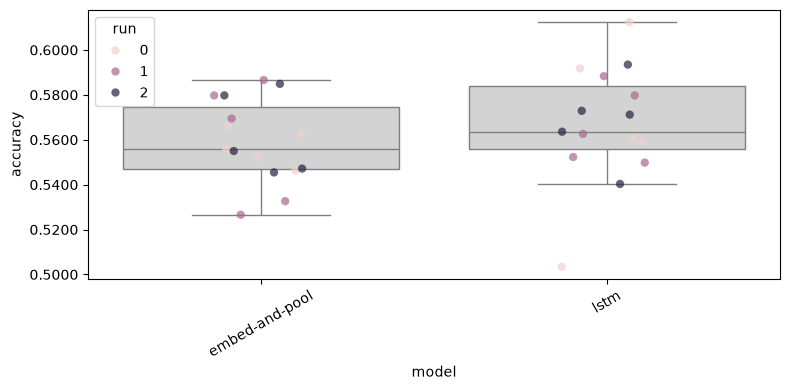

In [56]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(my_classifiers))

In [57]:
em00 = Project2.experiment.load(f"results/embed-and-pool/seed-0/fold-0/model", trained_emb_model)

In [58]:
em00_dt_logprobs = Project2.experiment.predict_logprobs(em00, tokenizer_for_bow, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
em00_dt_logprobs.shape

(300, 3)

In [59]:
from sklearn.metrics import classification_report

In [60]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(em00_dt_logprobs, -1), target_names=outcome_space.names))

              precision    recall  f1-score   support

        none       0.41      0.28      0.33        58
     against       0.65      0.88      0.75       171
       favor       0.78      0.30      0.43        71

    accuracy                           0.63       300
   macro avg       0.61      0.48      0.50       300
weighted avg       0.63      0.63      0.59       300



In [61]:
rm00 = Project2.experiment.load(f"results/lstm/seed-0/fold-0/model", trained_emb_model)
rm00_dt_logprobs = Project2.experiment.predict_logprobs(rm00, tokenizer_for_rnn, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
rm00_dt_logprobs.shape

(300, 3)

In [62]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(rm00_dt_logprobs, -1), target_names=outcome_space.names))

              precision    recall  f1-score   support

        none       0.34      0.43      0.38        58
     against       0.68      0.53      0.59       171
       favor       0.39      0.52      0.45        71

    accuracy                           0.51       300
   macro avg       0.47      0.49      0.47       300
weighted avg       0.55      0.51      0.52       300



In [63]:
name_to_tokenizer = {
    'embed-and-pool': tokenizer_for_bow,
    'lstm': tokenizer_for_rnn,
}
eval_fold = 0

test_texts  = list(dataset["test"]["text"])
test_labels = np.array(dataset["test"]["label"], dtype=int)
test_topics = np.array(dataset["test"]["topic"])

def predict_labels(model_family, fold, texts):
    model = Project2.experiment.load(f"results/{model_family}/seed-0/fold-{fold}/model", trained_emb_model)
    logprobs = Project2.experiment.predict_logprobs(model, name_to_tokenizer[model_family], texts, 64, 'cpu')
    return np.argmax(logprobs, axis=-1)

test_preds = {name: predict_labels(name, eval_fold, test_texts) for name in name_to_tokenizer}

rows = []
for topic in ["all"] + [t.replace("stance_", "") for t in topics]:
    mask = np.ones(len(test_labels), dtype=bool) if topic == "all" else (test_topics == topic)
    for name, pred in test_preds.items():
        precision, recall, f1, _ = precision_recall_fscore_support(
            test_labels[mask], pred[mask], average="weighted", zero_division=0
        )
        rows.append({"Topic": topic, "Model": name,
                     "Precision": precision, "Recall": recall, "F1 Score": f1})

metrics_df = pd.DataFrame(rows).set_index(["Topic", "Model"])
display(metrics_df.round(4))

Precision  Recall  F1 Score
Topic    Model                                      
all      embed-and-pool     0.5972  0.6085    0.5642
         lstm               0.5856  0.5516    0.5626
abortion embed-and-pool     0.5465  0.6321    0.5717
         lstm               0.6240  0.5321    0.5575
atheism  embed-and-pool     0.7567  0.7364    0.6831
         lstm               0.6715  0.6409    0.6547
climate  embed-and-pool     0.6927  0.4201    0.4967
         lstm               0.7100  0.6036    0.6401
feminist embed-and-pool     0.5095  0.5930    0.5404
         lstm               0.5744  0.4561    0.4789
hillary  embed-and-pool     0.5784  0.6136    0.5470
         lstm               0.5727  0.5661    0.5690

In [64]:
from pathlib import Path

experiment_name = "Experiment_A"

output_dir = Path("experiments")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_df.to_csv(output_dir / f"{experiment_name}_metrics.csv")

print("Saved successfully!")

Saved successfully!


In [65]:
# we will be using textstat as a way to otain some descriptive features of text; 
# we encourage you to look for things that are meaningful to your own task/dataset
# this is just to demo the kind of thing you can do 
import textstat  


table = []
systems = dict()
items = dict()

# each model uses a certain tokenizer, and we don't want to accidentally use the wrong one
name_to_tokenizer = {
    'embed-and-pool': tokenizer_for_bow, 
    'lstm': tokenizer_for_rnn
}

for model_family, model_data in my_classifiers.items(): # for all our trained classifiers
    for run, (seed, run_data) in enumerate(zip(my_seeds, model_data)):
        # we get the devtest set that we kep aside for each run
        # both texts and labels
        run_texts = [text for text, label in my_test_sets[run]['devtest']]
        run_labels = np.array([label for text, label in my_test_sets[run]['devtest']], dtype=int)
        
        for fold in range(num_folds):            
            # load our model
            trained_nn = Project2.experiment.load(f"results/{model_family}/seed-{seed}/fold-{fold}/model", trained_emb_model)
            # test it on the devtest
            logprobs = Project2.experiment.predict_logprobs(
                trained_nn, 
                name_to_tokenizer[model_family], 
                run_texts, 
                64, 
                'cpu'
            )
            preds = np.argmax(logprobs, -1)
    
            # then featurize the texts and compute the correctness flags
            for i in range(len(preds)):                
                                
                # find an int id for each system
                sid = systems.get(model_family, None)                
                if sid is None:
                    sid = len(systems)
                    systems[model_family] = sid
                # find an int id for each item
                item = my_test_sets[run]['devtest_ids'][i]                  
                item_id = items.get(item, None)                
                if item_id is None:
                    item_id = len(items)
                    items[item] = item_id

                # text, pred, and label
                x = run_texts[i]
                y_ = preds[i]
                y = run_labels[i]

                # put it all in a table, along with some features
                table.append([
                    model_family, 
                    item,
                    sid, 
                    item_id, 
                    run, 
                    fold, 
                    y, 
                    y_, 
                    int(y == y_), # correctness flag
                    # some features
                    textstat.lexicon_count(x),
                    textstat.flesch_reading_ease(x),
                    textstat.reading_time(x),
                    textstat.flesch_kincaid_grade(x)
                ])

df = pd.DataFrame(table, columns=['system', 'item', 'system_id', 'item_id', 'run', 'fold',  'label', 'pred', 'correct', 'lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade'])
df

,system,item,system_id,item_id,run,fold,label,pred,correct,lexicon_count,flesch_reading_ease,reading_time,flesch_kincaid_grade
0,embed-and-pool,1057,0,0,0,0,0,1,0,13,57.068269,1.02830,6.914231
1,embed-and-pool,938,0,1,0,0,0,1,0,8,92.965000,0.54353,2.280000
2,embed-and-pool,1228,0,2,0,0,1,1,1,21,42.615714,1.96846,9.054286
3,embed-and-pool,683,0,3,0,0,1,1,1,25,68.939500,1.52776,6.749000
4,embed-and-pool,282,0,4,0,0,1,1,1,22,80.677727,1.30741,7.471818
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,lstm,376,1,376,2,4,0,0,1,6,102.045000,0.42601,0.516667
8996,lstm,734,1,709,2,4,1,0,0,6,73.845000,0.41132,4.450000
8997,lstm,466,1,710,2,4,1,1,1,17,19.054559,1.79218,12.713235
8998,lstm,738,1,711,2,4,1,1,1,17,35.309412,1.52776,12.557647


In [66]:
# Run with your inputs.
mcmc = Project2.analysis.fit_bda_model(
    num_systems=len(systems), 
    sys_id=df['system_id'].to_numpy(), 
    # for features we have the one-hot encoding of the prediction (so we can learn if a system is better/worse at specific classes
    # as well as a few features that capture interesting aspects of the input text
    features=np.hstack(
        [
            Project2.analysis.one_hot(df['pred'].to_numpy(), len(outcome_space)),  # K-dimensional pred indicator
            df[['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade']].to_numpy() # 4 other features
        ]
    ),
    correctness=df['correct'].to_numpy(),
    num_chains=2
)
mcmc.print_summary()

sample: 100%|██████████| 2000/2000 [01:10<00:00, 28.30it/s, 127 steps of size 2.54e-02. acc. prob=0.93]



                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      0.36      0.63      0.38     -0.62      1.42   1276.65      1.00
 sys_shift[0]      0.07      0.63      0.06     -1.00      1.02   1281.53      1.00
 sys_shift[1]      0.02      0.63      0.00     -1.07      0.96   1278.32      1.00
       w[0,0]     -0.22      0.45     -0.24     -0.97      0.50   1038.77      1.00
       w[0,1]      0.12      0.56      0.08     -0.83      1.00   1040.08      1.00
       w[0,2]      0.15      0.43      0.12     -0.60      0.80   1052.69      1.00
       w[0,3]      0.29      0.09      0.29      0.15      0.44   1269.57      1.00
       w[0,4]     -0.25      0.10     -0.26     -0.43     -0.09   1340.20      1.00
       w[0,5]     -0.21      0.09     -0.21     -0.36     -0.08   1277.35      1.00
       w[0,6]     -0.27      0.09     -0.27     -0.42     -0.12   1542.51      1.00
       w[1,0]     -0.30      0.48     -0.29     -1.02      0.43   1149.19  

In [67]:
posterior = mcmc.get_samples()
print("Weight samples:", posterior["w"].shape)
print("System shift samples:", posterior["sys_shift"].shape)
print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

Weight samples: (2000, 2, 7)
System shift samples: (2000, 2)
Divergences: 0


In [68]:
posterior_data = Project2.analysis.posterior_to_arviz(
    mcmc,
    # you need only name the systems
    system_names=[name for name, _ in sorted(systems.items(), key=lambda pair: pair[1])],
    # and the features
    feature_names=[f"pred:{n}" for n in outcome_space.names] + ['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade']
) 

In [69]:
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

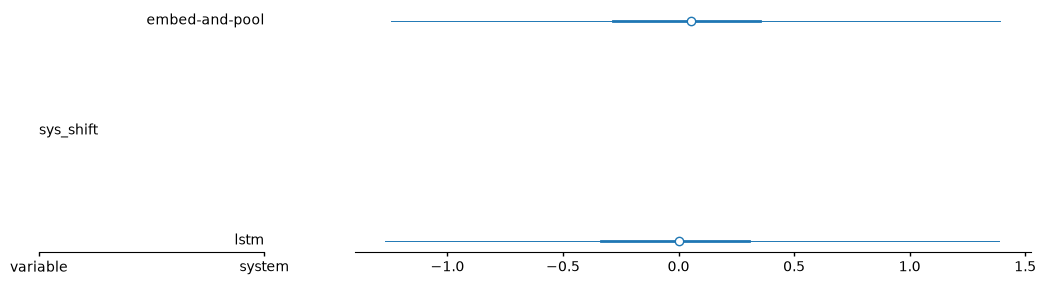

In [70]:
az.plot_forest(
    posterior_data, 
    var_names=['sys_shift'],    
    combined=True,           # Combine chains
    **az_stats_params
)

It's easier to appreciate posterior accuracy. This will not differ much from what you saw with `plot_box_and_points`:

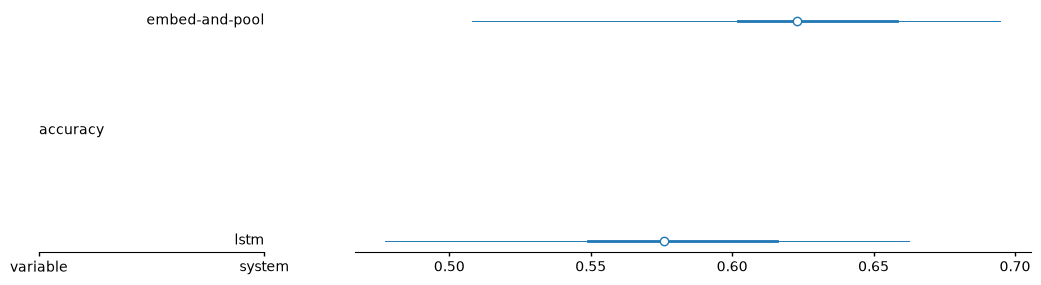

In [71]:
az.plot_forest(
    posterior_data, 
    var_names=['accuracy'],    
    combined=True,           # Combine chains
    **az_stats_params
)

And the most interesting thing this model offers, like any other linear model, is a view of the importance of the different features:

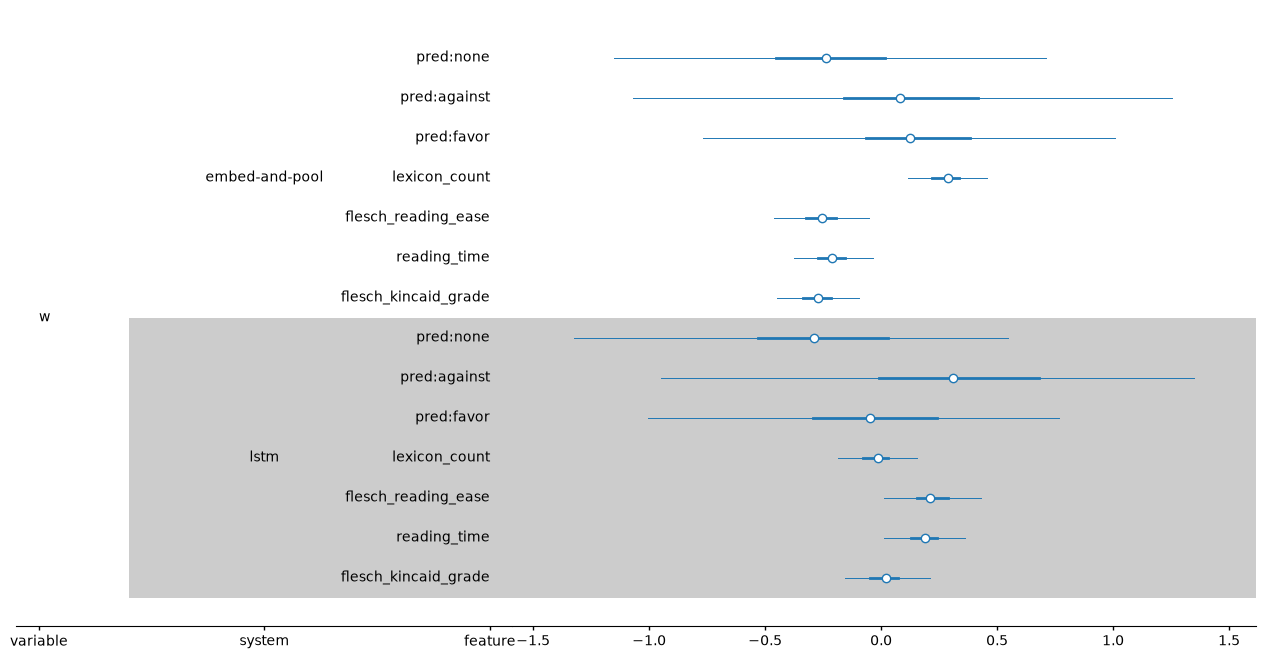

In [72]:
az.plot_forest(
    posterior_data, 
    var_names=['w'],    
    combined=True,           # Combine chains    
    shade_label="system",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],  # Label panel : interval panel
        "layout": "none",
    },
    **az_stats_params,
)

You might find it easier to group the plots differently, putting systems side by side for each feature:

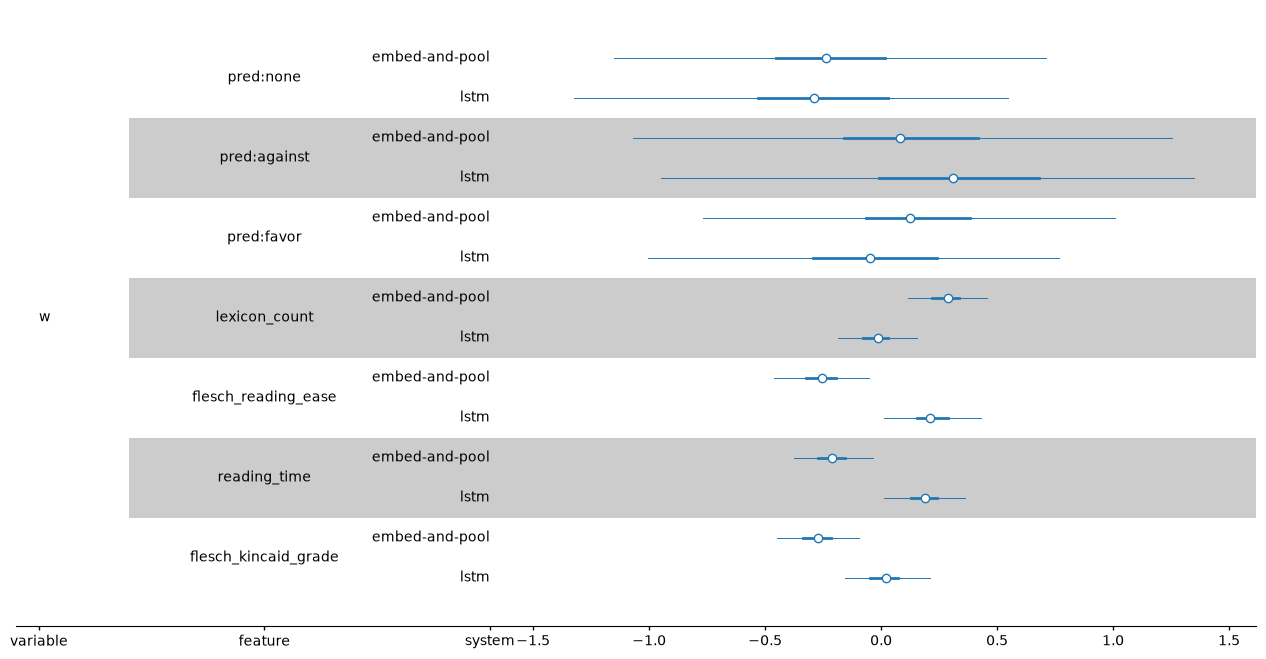

In [73]:
# Create a plotting copy containing only w, with reordered dimensions.
plot_data = posterior_data.copy()
plot_data["posterior"] = (
    posterior_data.posterior["w"]
    .transpose("chain", "draw", "feature", "system")
    .to_dataset()
)

az.plot_forest(
    plot_data,
    var_names=["w"],
    combined=True,
    shade_label="feature",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],
        "layout": "none",
    },
    **az_stats_params,
)

embed-and-pool selected: [38, 24, 185]
lstm selected: [38, 24, 200]

Tweet: we can address both climate change and sustainable development with the same measures <user> <hashtag> s d gs <hashtag> climateaction <hashtag> cop<number> <allcaps>
Topic: climate
True stance: favor

embed-and-pool
Predicted: favor
Correct: True
LIME: [(np.str_('<hashtag>'), -0.12260008368427064), (np.str_('climate'), 0.10913828297161256), (np.str_('sustainable'), 0.07917286319158091), (np.str_('cop<number>'), -0.06284507837754462), (np.str_('development'), 0.06196931361807902), (np.str_('<user>'), -0.03642762112385103), (np.str_('measures'), 0.02304728862654993), (np.str_('gs'), -0.019717168488110864), (np.str_('<allcaps>'), -0.018931281510496115), (np.str_('address'), -0.016633994626986906)]


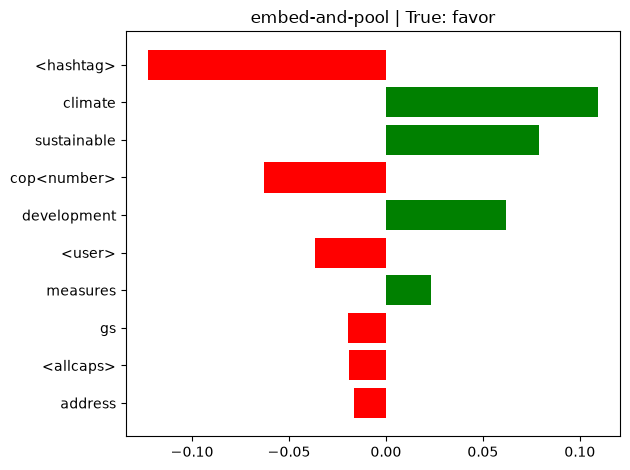


lstm
Predicted: favor
Correct: True
LIME: [(np.str_('<hashtag>'), -0.13564415155353635), (np.str_('cop<number>'), -0.12979862576178008), (np.str_('climateaction'), -0.12845374969593445), (np.str_('climate'), 0.07666314558328982), (np.str_('<allcaps>'), 0.0675920760007877), (np.str_('sustainable'), 0.05427751636486967), (np.str_('same'), -0.027958180602091924), (np.str_('development'), 0.027518183517623904), (np.str_('d'), -0.026768850834366042), (np.str_('and'), 0.023260827815294254)]


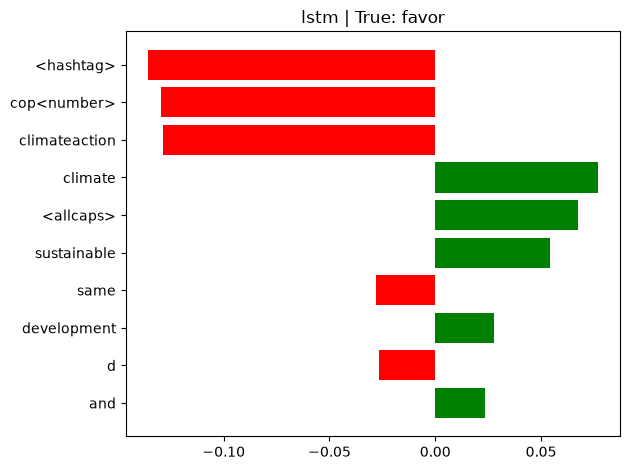


Tweet: join the hillary team now and come to the jefferson county phone bank tomorrow from <number><number> at bliss studio in fairfield!
Topic: hillary
True stance: favor

embed-and-pool
Predicted: against
Correct: False
LIME: [(np.str_('hillary'), 0.10089595927385249), (np.str_('<number><number>'), 0.07937874213040444), (np.str_('team'), -0.060952919008907355), (np.str_('studio'), -0.0521431377468303), (np.str_('phone'), 0.0402773978452559), (np.str_('tomorrow'), -0.03554278426163097), (np.str_('join'), -0.0341390831292435), (np.str_('bliss'), 0.029153428330889186), (np.str_('come'), -0.029092058631242732), (np.str_('county'), -0.027230925489430596)]


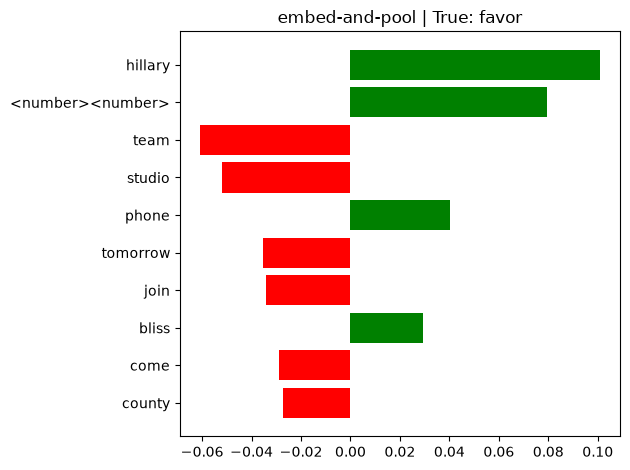


lstm
Predicted: favor
Correct: True
LIME: [(np.str_('fairfield!'), -0.188096802041621), (np.str_('in'), 0.13661370749636098), (np.str_('county'), 0.09908954485645717), (np.str_('bliss'), 0.09768539592459669), (np.str_('at'), 0.09402182927673992), (np.str_('bank'), -0.05580562975074061), (np.str_('and'), 0.05552484638177504), (np.str_('hillary'), 0.05529122249281073), (np.str_('studio'), -0.04768167786614615), (np.str_('tomorrow'), 0.03295290462554477)]


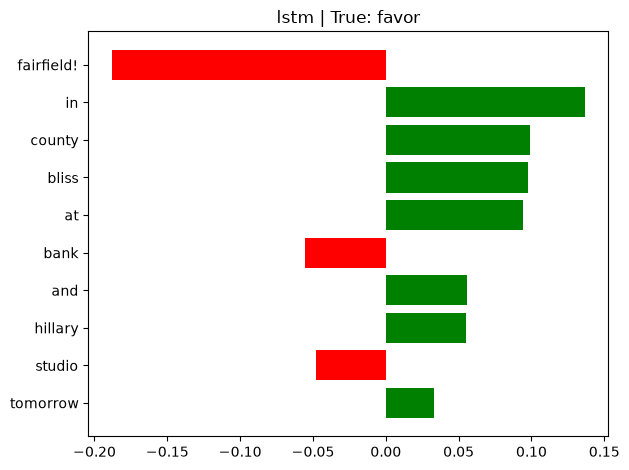


Tweet: people don't care about things that don't effect men which is the same reason it's sexist we don't cover birth control
Topic: abortion
True stance: against

embed-and-pool
Predicted: against
Correct: True
LIME: [(np.str_('birth'), 0.09530594450359259), (np.str_('effect'), -0.08448722631204099), (np.str_('care'), -0.05660940151740053), (np.str_('men'), 0.0546358354186517), (np.str_('control'), 0.0365578597314965), (np.str_('people'), -0.03338250182602706), (np.str_('reason'), 0.024187264378436792), (np.str_('sexist'), -0.009478984146038443), (np.str_('things'), -0.007691471128068578), (np.str_('the'), -0.006630819431224471)]


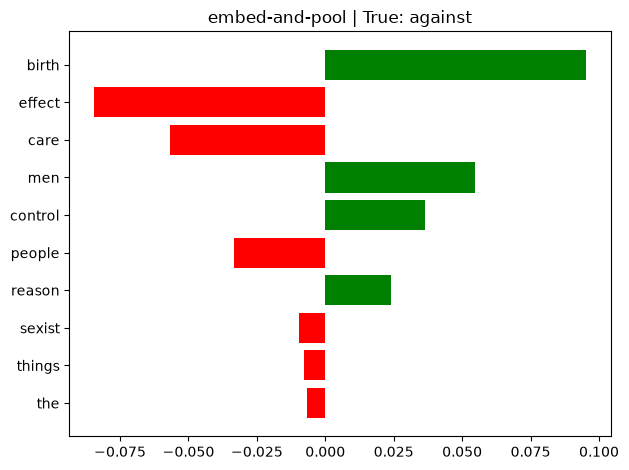


lstm
Predicted: favor
Correct: False
LIME: [(np.str_("don't"), 0.2363710983787307), (np.str_('control'), 0.10723377178248633), (np.str_('cover'), -0.0983344028147404), (np.str_('sexist'), -0.07863232917734676), (np.str_('we'), -0.07115799611657415), (np.str_("it's"), 0.06528952452902059), (np.str_('same'), -0.05767098468727099), (np.str_('effect'), 0.054241513190474766), (np.str_('care'), 0.0404347534461675), (np.str_('reason'), -0.0392212726693722)]


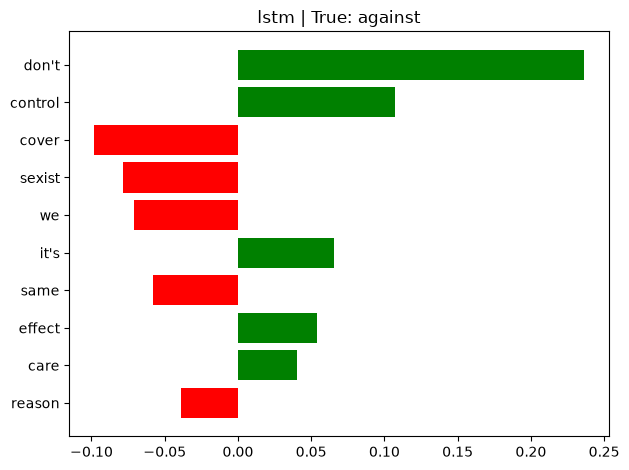


Tweet: dear to who it may concern;"you <allcaps> stand up for my right to live. <hashtag> baby <hashtag> murder <hashtag> right to life <hashtag> unborn <hashtag> womensrights <hashtag> legal
Topic: abortion
True stance: against

embed-and-pool
Predicted: against
Correct: True
LIME: [(np.str_('<hashtag>'), -0.16568884430705808), (np.str_('unborn'), 0.11860795497602668), (np.str_('murder'), 0.061039182207718236), (np.str_('right'), -0.043791926606176354), (np.str_('stand'), 0.025691738315784057), (np.str_('womensrights'), -0.024538160194218495), (np.str_('live.'), -0.021808797373695385), (np.str_('dear'), 0.02129486427797163), (np.str_('life'), 0.01021704052253307), (np.str_('concern;"you'), -0.00668482449568024)]


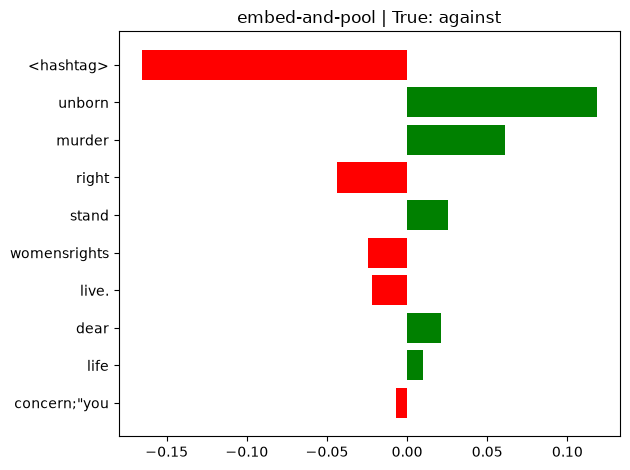


lstm
Predicted: against
Correct: True
LIME: [(np.str_('unborn'), 0.29146218783622174), (np.str_('womensrights'), -0.2732654420122533), (np.str_('legal'), -0.2144694387273631), (np.str_('murder'), 0.13706943755155548), (np.str_('<hashtag>'), -0.0694209789257542), (np.str_('to'), -0.06862754810076933), (np.str_('life'), 0.053250219835594706), (np.str_('concern;"you'), 0.04473630823010144), (np.str_('dear'), 0.033773302887420885), (np.str_('baby'), 0.022281253193481225)]


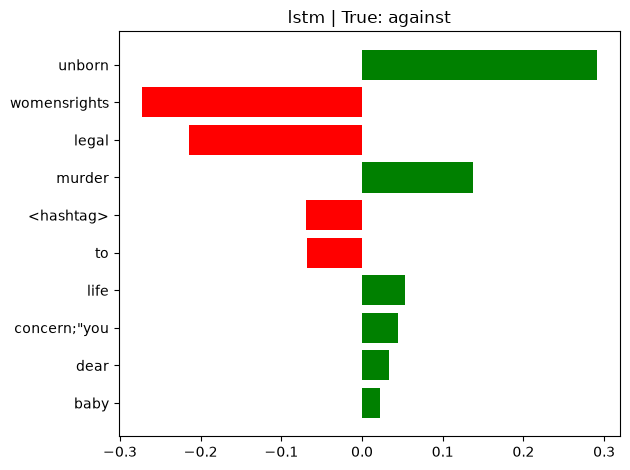


Tweet: paul leadley talking about <hashtag> biodiversity scenarios under <hashtag> h< n u m b e r> <hashtag> cfcc<number> <allcaps>
Topic: climate
True stance: favor

embed-and-pool
Predicted: against
Correct: False
LIME: [(np.str_('<hashtag>'), -0.07996566255824059), (np.str_('cfcc<number>'), 0.040479317070526676), (np.str_('talking'), -0.03995394600185125), (np.str_('biodiversity'), -0.02311637775515639), (np.str_('r>'), 0.021146149082626884), (np.str_('u'), 0.021127635841616314), (np.str_('<allcaps>'), 0.019663826280657135), (np.str_('e'), 0.01900554398867768), (np.str_('n'), 0.014847007805968487), (np.str_('b'), 0.012297863958801556)]


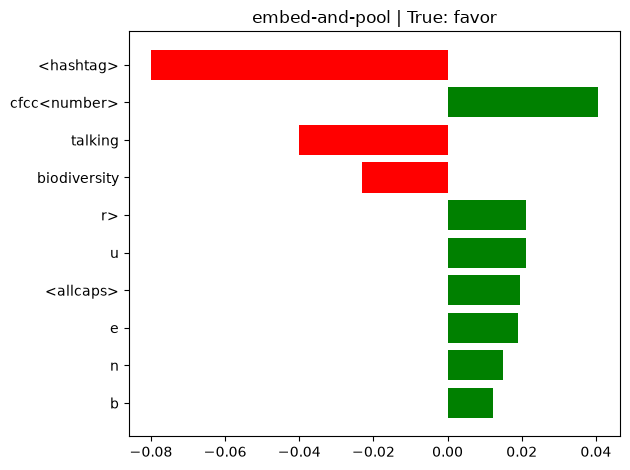


lstm
Predicted: favor
Correct: True
LIME: [(np.str_('biodiversity'), 0.16179011446831362), (np.str_('<hashtag>'), -0.11028637858527511), (np.str_('cfcc<number>'), -0.08672974230523876), (np.str_('<allcaps>'), 0.058034010148672835), (np.str_('scenarios'), -0.05532498986154661), (np.str_('under'), 0.05387625269887933), (np.str_('e'), 0.04446904167342213), (np.str_('n'), -0.032053612196168924), (np.str_('u'), -0.03136337743090139), (np.str_('r>'), -0.031011896916465012)]


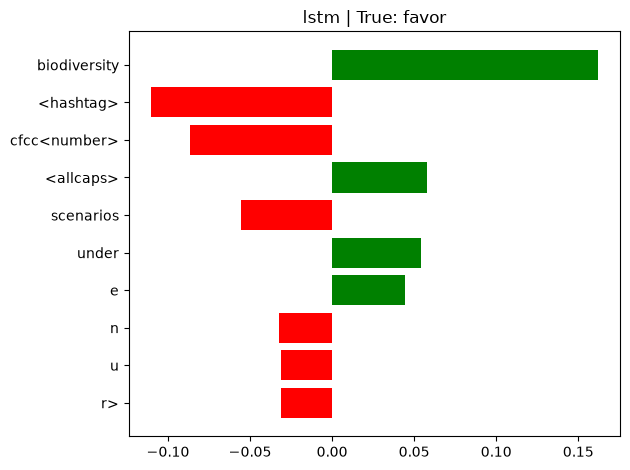


Tweet: the idea that a "fetus" isn't human is outrageous, i mean what else would it be? a dog? a dragon? the unborn are human <allcaps> beings <allcaps>!
Topic: abortion
True stance: against

embed-and-pool
Predicted: against
Correct: True
LIME: [(np.str_('unborn'), 0.14021673094001888), (np.str_('idea'), -0.04991975334475539), (np.str_('else'), -0.033772442672596215), (np.str_('mean'), -0.025593913203297), (np.str_('dragon?'), 0.024585502343944066), (np.str_('dog?'), -0.02438209303148618), (np.str_('beings'), 0.016649261524663183), (np.str_('would'), -0.016287571442346056), (np.str_('"fetus"'), 0.009333397790711028), (np.str_('is'), 0.006337125031042044)]


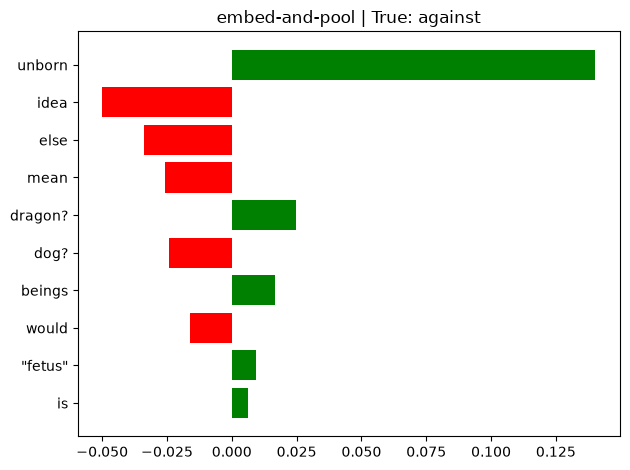


lstm
Predicted: favor
Correct: False
LIME: [(np.str_('unborn'), -0.21656736189157078), (np.str_('human'), 0.19670386024643918), (np.str_('beings'), 0.09909188364104081), (np.str_('dog?'), 0.0713937012176608), (np.str_('the'), 0.04996578623968203), (np.str_('else'), 0.04500231820852823), (np.str_('<allcaps>!'), -0.03920441240884009), (np.str_('"fetus"'), -0.03570255928019683), (np.str_('dragon?'), -0.027936747143461095), (np.str_('a'), -0.024006348557390637)]


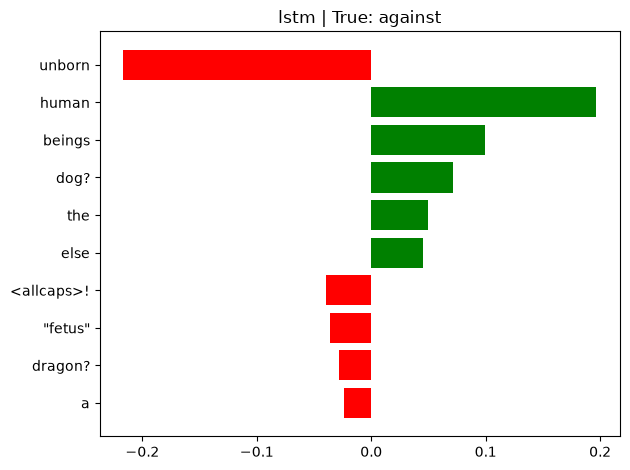


Tweet: the <hashtag> rally< n u m b e r>life shows yet again what little support these people have. <hashtag> repealthe< n u m b e r>th
Topic: abortion
True stance: against

embed-and-pool
Predicted: against
Correct: True
LIME: [(np.str_('<hashtag>'), -0.04689598992711756), (np.str_('r>life'), 0.04165286411230584), (np.str_('rally<'), -0.03967674228872048), (np.str_('u'), 0.029718113387469137), (np.str_('e'), 0.02583777609928968), (np.str_('shows'), -0.019062196701097676), (np.str_('n'), 0.016329518959800143), (np.str_('b'), 0.013934944571811849), (np.str_('little'), -0.013338046443671897), (np.str_('repealthe<'), 0.00806874916324478)]


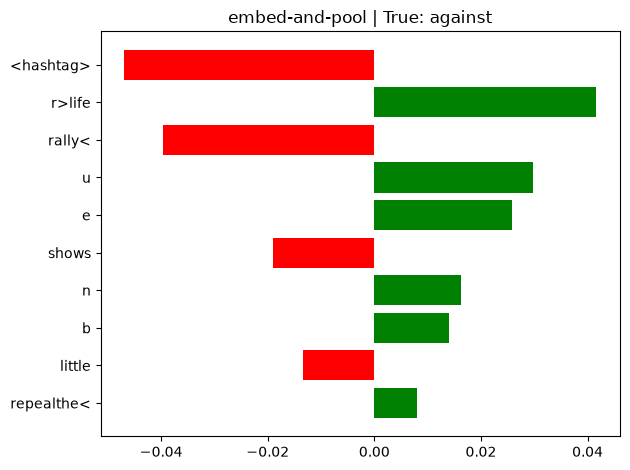


lstm
Predicted: none
Correct: False
LIME: [(np.str_('r>th'), 0.20507550693786802), (np.str_('e'), -0.06786566469077127), (np.str_('rally<'), 0.03473279574812623), (np.str_('m'), -0.031043397700296342), (np.str_('<hashtag>'), 0.02913468305104027), (np.str_('little'), 0.02880845304702347), (np.str_('have.'), -0.019741124883871544), (np.str_('these'), 0.017427856342179186), (np.str_('b'), -0.016355545016224014), (np.str_('repealthe<'), -0.014405657753368018)]


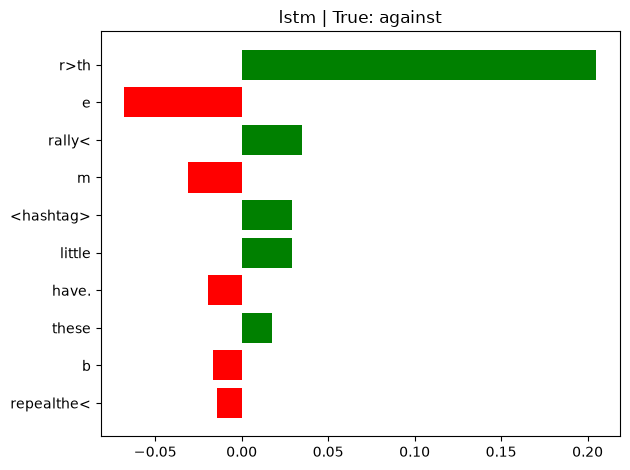

In [ ]:
from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick

# prediction function
def pool_proba(texts):
    logp = Project2.experiment.predict_logprobs(
        em00, tokenizer_for_bow, list(texts), 64, "cpu"
    )
    return np.exp(np.asarray(logp))

def lstm_proba(texts):
    # LIME may remove every word or produce text
    # that contains no valid tokens.
    safe_texts = [
        text if len(tokenizer_for_rnn.ids(text)) > 0 else "<unk>"
        for text in texts
    ]

    logp = Project2.experiment.predict_logprobs(
        rm00,
        tokenizer_for_rnn,
        safe_texts,
        64,
        "cpu"
    )

    return np.exp(np.asarray(logp))

assert len(tokenizer_for_rnn.ids("<unk>")) > 0
models = {
    "embed-and-pool": pool_proba,
    "lstm": lstm_proba
}


# data for error analysis
analysis_pairs = my_test_sets[0]["devtest"]

texts = np.array(
    [text for text, label in analysis_pairs]
)
labels = np.array(
    [label for text, label in analysis_pairs]
)

# Use the same candidate tweets for both models
rng = np.random.default_rng(42)
candidate_ids = rng.choice(
    len(texts),
    size=min(20, len(texts)),
    replace=False
)
candidate_texts = texts[candidate_ids]

# submodular pick
selected = {}

for name, predict_fn in models.items():
    explainer = LimeTextExplainer(
        class_names=list(outcome_space.names),
        split_expression=r"\s+",
        random_state=42
    )

    sp = SubmodularPick(
        explainer,
        candidate_texts,
        predict_fn,
        method="full",
        num_exps_desired=3,
        num_features=8,
        num_samples=300
    )

    # With method="full", V indexes candidate_texts
    selected[name] = [
        int(candidate_ids[i]) for i in sp.V
    ]

    print(name, "selected:", selected[name])

# disagreements
pool_preds = pool_proba(texts).argmax(axis=1)
lstm_preds = lstm_proba(texts).argmax(axis=1)

# Examples where exactly one model is correct
disagreement_ids = np.where(
    (pool_preds == labels) != (lstm_preds == labels)
)[0]

extra_ids = rng.choice(
    disagreement_ids,
    size=min(3, len(disagreement_ids)),
    replace=False
)

# Union of SP-LIME examples and disagreement examples
selected_ids = list(dict.fromkeys(
    selected["embed-and-pool"]
    + selected["lstm"]
    + extra_ids.tolist()
))

# explain tweets
for i in selected_ids:
    text = texts[i]
    true_label = int(labels[i])

    # Retrieve topic from the original test dataset
    original_id = my_test_sets[0]["devtest_ids"][i]
    topic = dataset["test"][int(original_id)]["topic"]

    print("\n" + "=" * 60)
    print("Tweet:", text)
    print("Topic:", topic)
    print("True stance:", outcome_space.names[true_label])

    for name, predict_fn in models.items():
        probs = predict_fn([text])[0]
        pred = int(np.argmax(probs))

        explainer = LimeTextExplainer(
            class_names=list(outcome_space.names),
            split_expression=r"\s+",
            random_state=42
        )

        exp = explainer.explain_instance(
            text,
            predict_fn,
            labels=(pred,),
            num_features=10,
            num_samples=500
        )

        print(f"\n{name}")
        print("Predicted:", outcome_space.names[pred])
        print("Correct:", pred == true_label)
        print("LIME:", exp.as_list(label=pred))

        exp.as_pyplot_figure(label=pred)
        plt.title(f"{name} | True: {outcome_space.names[true_label]}")
        plt.tight_layout()
        plt.show()

In [75]:
# Same 300 development-test examples for both systems
pairs = my_test_sets[0]["devtest"]
texts = [text for text, label in pairs]
labels = np.array([label for text, label in pairs])
ids = my_test_sets[0]["devtest_ids"]

pool_preds = np.argmax(em00_dt_logprobs, axis=1)
lstm_preds = np.argmax(rm00_dt_logprobs, axis=1)

errors = pd.DataFrame({
    "text": texts,
    "topic": [dataset["test"][int(i)]["topic"] for i in ids],
    "label": [outcome_space.name(int(y)) for y in labels],
    "pool_correct": pool_preds == labels,
    "lstm_correct": lstm_preds == labels
})

# Linguistic characteristics
errors["word_count"] = errors["text"].str.split().str.len()

errors["length_group"] = pd.cut(
    errors["word_count"],
    bins=[-1, 10, 20, float("inf")],
    labels=["short", "medium", "long"]
)

errors["negation"] = errors["text"].str.contains(
    r"\b(?:not|never|no|don't|isn't|can't|won't)\b",
    regex=True
)

errors["hashtag"] = errors["text"].str.contains(
    "<hashtag>", regex=False
)

errors["question"] = errors["text"].str.contains(
    "?", regex=False
)

unk_id = trained_emb_model.vocab.default_index

errors["has_oov"] = [
    any(i == unk_id for i in tokenizer_for_bow.ids(t))
    for t in texts
]

# Compare performance for each subgroup
for feature in [
    "topic", "label", "length_group",
    "negation", "hashtag", "question", "has_oov"
]:
    result = errors.groupby(feature, observed=True).agg(
        n=("text", "size"),
        pool_accuracy=("pool_correct", "mean"),
        lstm_accuracy=("lstm_correct", "mean")
    )

    result["LSTM_minus_pool"] = (
        result["lstm_accuracy"] - result["pool_accuracy"]
    )

    print(f"\nFeature: {feature}")
    display(result.round(3))


Feature: topic


,n,pool_accuracy,lstm_accuracy,LSTM_minus_pool
topic,,,,
abortion,70,0.614,0.500,-0.114
atheism,42,0.667,0.595,-0.071
climate,41,0.537,0.512,-0.024
feminist,64,0.672,0.438,-0.234
hillary,83,0.627,0.518,-0.108



Feature: label


,n,pool_accuracy,lstm_accuracy,LSTM_minus_pool
label,,,,
against,171,0.883,0.526,-0.357
favor,71,0.296,0.521,0.225
none,58,0.276,0.431,0.155



Feature: length_group


,n,pool_accuracy,lstm_accuracy,LSTM_minus_pool
length_group,,,,
short,28,0.536,0.464,-0.071
medium,137,0.613,0.533,-0.080
long,135,0.659,0.489,-0.170


... (4 outputs left out)


Feature: question


,n,pool_accuracy,lstm_accuracy,LSTM_minus_pool
question,,,,
False,251,0.625,0.546,-0.080
True,49,0.633,0.306,-0.327



Feature: has_oov


,n,pool_accuracy,lstm_accuracy,LSTM_minus_pool
has_oov,,,,
False,214,0.636,0.537,-0.098
True,86,0.605,0.430,-0.174
